In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-paper')

In [2]:
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
from src.utils.util import set_labels

In [3]:
exset1 = ExperimentSet(PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'cloud_motion')
exset1.set_retrieval_list()
exset1.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])
exset1.add_retrieval(PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11' / 'default', iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V12'
exset2 = ExperimentSet(es_dir)
exset2.set_retrieval_list()
exset2.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [5]:
def misr_S_1(y):
    return np.diag(1 / (0.04 * y)**2)

exp_name = np.array([])
chi2_exp = np.array([])
u = []
v = []
version = []
# for r in list(exset1.retrievals.values()):
#     chi2_exp_tmp = r.get_chi2(misr_S_1, 'I')
#     exp_name = np.append(exp_name, r.exp_name)
#     chi2_exp = np.append(chi2_exp, chi2_exp_tmp)
#     u.append(r.sensors_retrieval['MISR']['sensor_list'][0].wind_correction_u)
#     v.append(r.sensors_retrieval['MISR']['sensor_list'][0].wind_correction_v)
#     version.append('V11')
for r in list(exset2.retrievals.values()):
    chi2_exp_tmp = r.get_chi2(misr_S_1, 'I')
    exp_name = np.append(exp_name, r.exp_name)
    chi2_exp = np.append(chi2_exp, chi2_exp_tmp)
    u.append(r.sensors_retrieval['MISR']['sensor_list'][0].wind_correction_u)
    v.append(r.sensors_retrieval['MISR']['sensor_list'][0].wind_correction_v)
    version.append('V12')

df_overall = pd.DataFrame({'version':version, 'exp_name':exp_name, 'u':u, 'v':v, 'chi2':chi2_exp}).set_index(['version', 'exp_name'])

In [6]:
df_overall

u    v       chi2
version exp_name                          
V12     ATM            1.9  4.7  15.433424
        ATP            0.8 -0.8  17.757221
        CTM           -0.2  2.3  15.793466
        CTP            2.9  1.6  24.039770
        ATM_unc        1.9  4.7  15.424694
        ATP_unc        0.8 -0.8  15.152351
        CTM_unc       -0.2  2.3  17.765820
        CTP_unc        2.9  1.6  23.353095
        default        1.4  1.9  13.813153
        unconstrained  1.4  1.9  14.935229

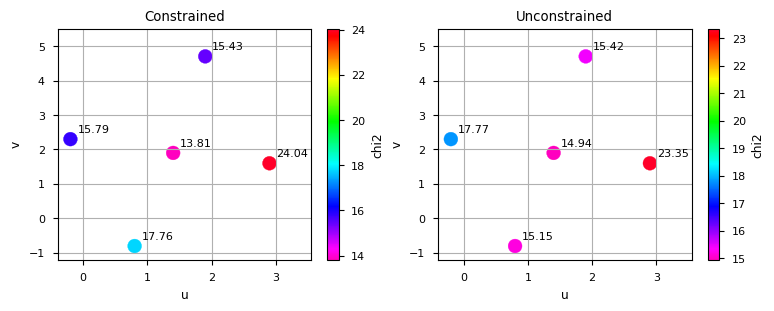

In [8]:
cmap = 'gist_rainbow_r'
f, ax = plt.subplots(1, 2, figsize=(9,3))

df1 = df_overall.loc[[
    # ('V11', 'ATM'),
    # ('V11', 'ATP'),
    # ('V11', 'CTM'),
    # ('V11', 'CTP'),
    # ('V11', 'default'),
    ('V12', 'ATM'),
    ('V12', 'ATP'),
    ('V12', 'CTM'),
    ('V12', 'CTP'),
    ('V12', 'default')
]]
df1.plot.scatter(x='u', y='v', c='chi2', s=100, cmap=cmap, ax=ax[0])
ax[0].set_title('Constrained')
for idx, row in df1.iterrows():
    ax[0].annotate(f"{row['chi2']:.2f}", (row['u'], row['v']),
                    textcoords="offset points", xytext=(5, 5), fontsize=8)

df2 = df_overall.loc[[
    ('V12', 'ATM_unc'),
    ('V12', 'ATP_unc'),
    ('V12', 'CTM_unc'),
    ('V12', 'CTP_unc'),
    ('V12', 'unconstrained')
]]
df2.plot.scatter(x='u', y='v', c='chi2', s=100, cmap=cmap, ax=ax[1])
ax[1].set_title('Unconstrained')
for idx, row in df2.iterrows():
    ax[1].annotate(f"{row['chi2']:.2f}", (row['u'], row['v']),
                    textcoords="offset points", xytext=(5, 5), fontsize=8)

for a in ax.flatten():
    a.grid()
    a.set_xlim([-0.4, 3.55])
    a.set_ylim([-1.2, 5.5])